In [60]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [61]:
df = pd.read_csv("churn_cleaned.csv")
sns.set_style("whitegrid")
df.shape

(7032, 20)

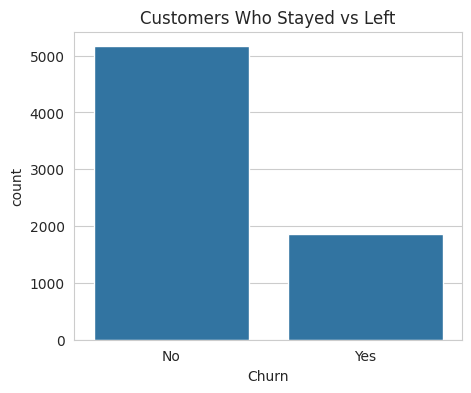

In [62]:
plt.figure(figsize=(5, 4))
sns.countplot(x='Churn', data=df)
plt.title("Customers Who Stayed vs Left")
plt.show()

**Observation:** Of about 7,000 customers, roughly 5,100 stayed and under 2,000 left. This is a churn rate of about **26.6%**, so roughly 1 in 4 customers leaves.

**Why it matters:** The data is imbalanced, with far more customers who stayed than left. When I build the prediction model later, accuracy alone could be misleading, so I will also check recall and precision.

In [63]:
df['Churn_flag'] = df['Churn'].map({'No': 0, 'Yes': 1})
print(df.groupby('Contract')['Churn_flag'].mean() * 100)

Contract
Month-to-month    42.709677
One year          11.277174
Two year           2.848665
Name: Churn_flag, dtype: float64


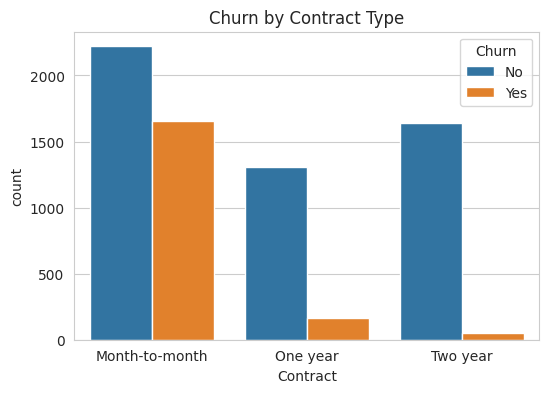

In [64]:
plt.figure(figsize=(6, 4))
sns.countplot(x='Contract', hue='Churn', data=df)
plt.title("Churn by Contract Type")
plt.show()

In [65]:
print(df.groupby('Contract')['Churn_flag'].mean() * 100)

Contract
Month-to-month    42.709677
One year          11.277174
Two year           2.848665
Name: Churn_flag, dtype: float64


In [66]:
df[df['Churn']=='Yes']['Contract'].value_counts(normalize=True)

,proportion
Contract,
Month-to-month,0.885500
One year,0.088818
Two year,0.025682


**Observation:** Month-to-month customers have by far the most churn: about 1,650 left, compared with roughly 165 on one-year contracts and about 50 on two-year contracts. Churn rates are **42.7%**, **11.3%** and **2.8%** respectively.

**Why it matters:** About **89%** of the customers who left were on month-to-month contracts. Customers without a long-term commitment can leave at any time, so this is the group where retention efforts will matter most.

**Action:** Offer discounts or perks to move month-to-month customers onto one-year or two-year contracts.

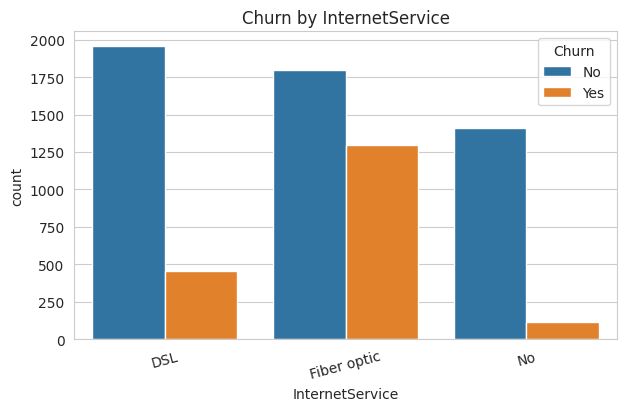

InternetService
DSL            18.998344
Fiber optic    41.892765
No              7.434211
Name: Churn_flag, dtype: float64


In [67]:
def churn_chart(col):
    plt.figure(figsize=(7, 4))
    sns.countplot(x=col, hue='Churn', data=df)
    plt.title(f"Churn by {col}")
    plt.xticks(rotation=15)
    plt.show()
    print(df.groupby(col)['Churn_flag'].mean() * 100)

churn_chart('InternetService')

**Observation:** Fiber optic customers churn at **41.9%**, DSL customers at **19.0%**, and customers with no internet service at only **7.4%**. Fiber optic also has the highest number of churned customers, about 1,300.

**Why it matters:** Fiber optic customers are more than twice as likely to leave as DSL customers. Earlier I found that fiber customers pay much more per month (about $91.50 vs $58.09 for DSL), so price or service quality may be a factor. The data shows an association, not proof of the cause.

**Action:** Investigate fiber optic customers further, for example by checking whether tech support or online security services affect their churn.

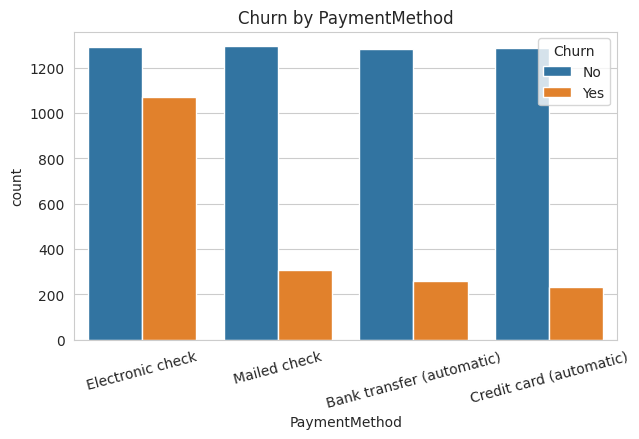

PaymentMethod
Bank transfer (automatic)    16.731518
Credit card (automatic)      15.253123
Electronic check             45.285412
Mailed check                 19.201995
Name: Churn_flag, dtype: float64


In [68]:
churn_chart('PaymentMethod')

**Observation:** Customers paying by electronic check churn at **45.3%**, far higher than mailed check (**19.2%**), bank transfer (**16.7%**) and credit card (**15.3%**). Electronic check customers are about 3 times as likely to leave as automatic-payment customers.

**Why it matters:** Customers on automatic payments (bank transfer or credit card) are the most stable. Electronic check customers may be less committed, or may face more payment friction, but the data alone doesn't show which.

**Action:** Encourage electronic check customers to switch to automatic payment, for example with a small bill discount.

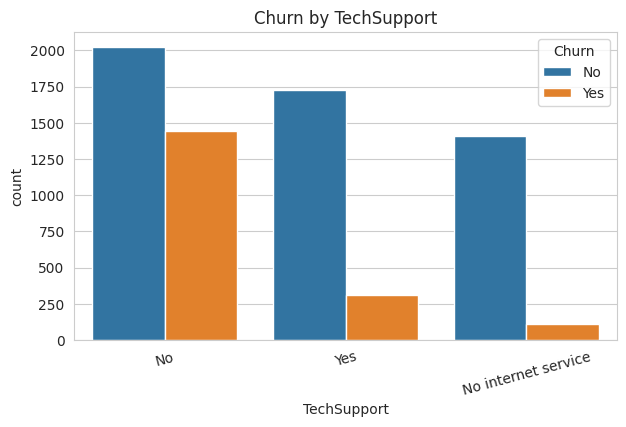

TechSupport
No                     41.647465
No internet service     7.434211
Yes                    15.196078
Name: Churn_flag, dtype: float64


In [69]:
churn_chart('TechSupport')

**Observation:** Customers without tech support churn at **41.6%**, compared with **15.2%** for customers who have it. (Customers with no internet service churn at only 7.4%, so I left them out of this comparison.)

**Why it matters:** Customers with tech support are almost 3 times less likely to leave, so support may help customers stay. This is an association, not proof that support causes retention.

**Action:** Offer free or discounted tech support trials to customers who don't have it, especially new ones.

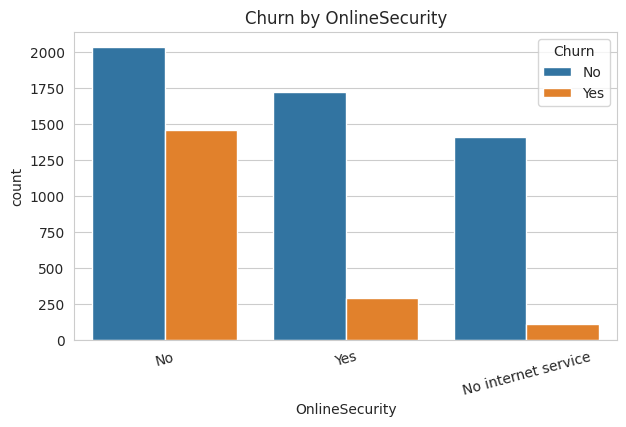

OnlineSecurity
No                     41.778667
No internet service     7.434211
Yes                    14.640199
Name: Churn_flag, dtype: float64


In [70]:
churn_chart('OnlineSecurity')

**Observation:** Customers without online security churn at **41.8%**, compared with **14.6%** for those who have it.

**Why it matters:** The pattern is almost identical to tech support: add-on services are linked with much lower churn. Customers who use more services may be more invested in the company.

**Action:** Bundle security and support services into plans to encourage customers to take them.

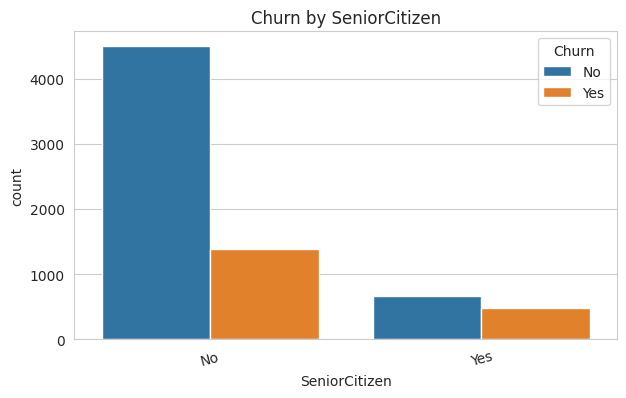

SeniorCitizen
No     23.650255
Yes    41.681261
Name: Churn_flag, dtype: float64


In [71]:
churn_chart('SeniorCitizen')

**Observation:** Senior citizens churn at **41.7%**, compared with **23.7%** for non-seniors, about 18 percentage points higher.

**Why it matters:** Seniors may need simpler plans or more support, but this analysis doesn't show the reason.

**Action:** Look at what services seniors use and consider simpler plans and dedicated support for them.

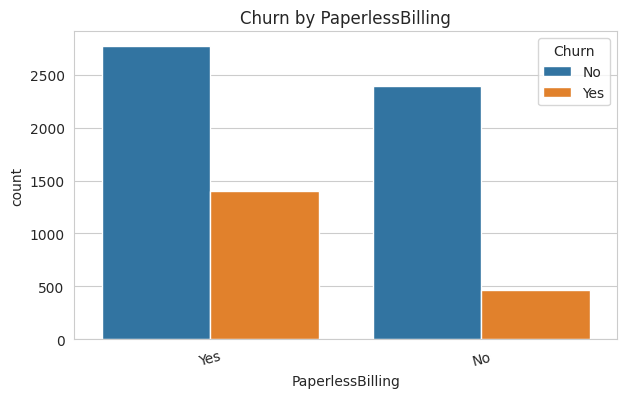

PaperlessBilling
No     16.375698
Yes    33.589251
Name: Churn_flag, dtype: float64


In [72]:
churn_chart('PaperlessBilling')

**Observation:** Customers with paperless billing churn at **33.6%**, about twice the rate of customers without it (**16.4%**).

**Why it matters:** Paperless billing itself is unlikely to cause churn. It probably overlaps with other factors, such as electronic check payment or newer, more digital customers, and I should check this before drawing conclusions.

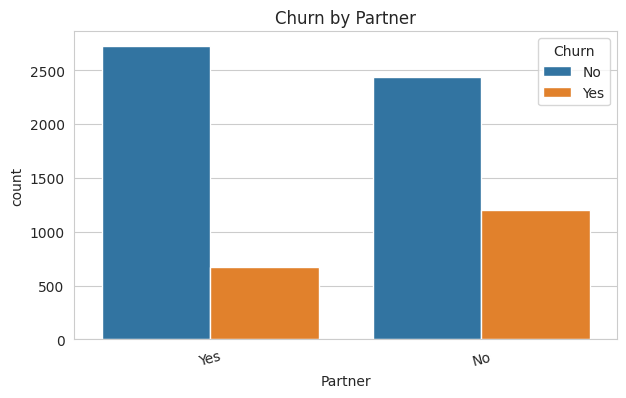

Partner
No     32.976092
Yes    19.717065
Name: Churn_flag, dtype: float64


In [73]:
churn_chart('Partner')

**Observation:** Customers without a partner churn at **33.0%**, compared with **19.7%** for those with a partner.

**Why it matters:** Customers with a partner may share the account and be less likely to switch, but the gap (about 13 points) is smaller than for contract type, tech support or payment method.

In [74]:
cols = ['PaymentMethod', 'TechSupport', 'OnlineSecurity',
        'SeniorCitizen', 'PaperlessBilling', 'Partner']

for col in cols:
    print(col)
    print((df.groupby(col)['Churn_flag'].mean() * 100).round(1))
    print()

PaymentMethod
PaymentMethod
Bank transfer (automatic)    16.7
Credit card (automatic)      15.3
Electronic check             45.3
Mailed check                 19.2
Name: Churn_flag, dtype: float64

TechSupport
TechSupport
No                     41.6
No internet service     7.4
Yes                    15.2
Name: Churn_flag, dtype: float64

OnlineSecurity
OnlineSecurity
No                     41.8
No internet service     7.4
Yes                    14.6
Name: Churn_flag, dtype: float64

SeniorCitizen
SeniorCitizen
No     23.7
Yes    41.7
Name: Churn_flag, dtype: float64

PaperlessBilling
PaperlessBilling
No     16.4
Yes    33.6
Name: Churn_flag, dtype: float64

Partner
Partner
No     33.0
Yes    19.7
Name: Churn_flag, dtype: float64



## Key Insights So Far

1. **Contract type is the strongest driver.** Month-to-month customers churn at 42.7% vs 2.8% for two-year contracts.
2. **Fiber optic customers churn the most (41.9%)** and also pay the highest bills.
3. **Add-on services are linked with lower churn.** Customers without tech support or online security churn about 3 times more.
4. **Electronic check users churn at 45.3%**, about 3 times the rate of automatic-payment customers.
5. **Seniors, paperless-billing customers and customers without a partner** churn more, but the gaps are smaller.
6. **Churn is concentrated** among customers with short commitments, no add-on services and manual payment methods.

**Next step:** Look at tenure and monthly charges, then build a model to predict churn.

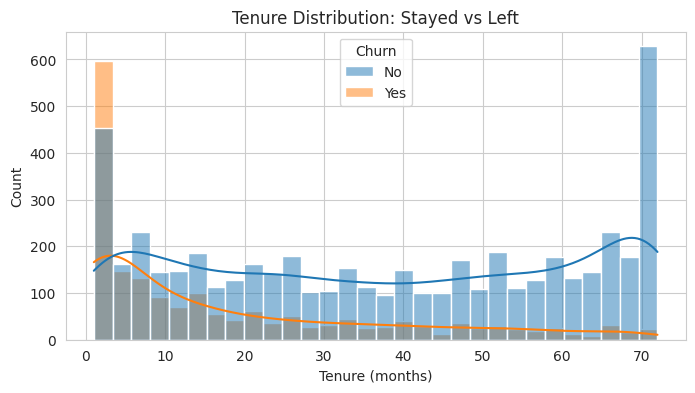

In [75]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x='tenure', hue='Churn', bins=30, kde=True)
plt.title("Tenure Distribution: Stayed vs Left")
plt.xlabel("Tenure (months)")
plt.show()

**Observation:** Customers who left have a much shorter tenure. The average tenure is **18.0 months** for churned customers and **37.7 months** for those who stayed. Churned customers are bunched at the low end of tenure, while customers who stayed are spread across the whole range, with a large group at 70+ months.

**Why it matters:** Churn is highest among newer customers, so the first months of the relationship are the critical window for retention.

**Action:** Build an onboarding and early-loyalty program for customers in their first year.

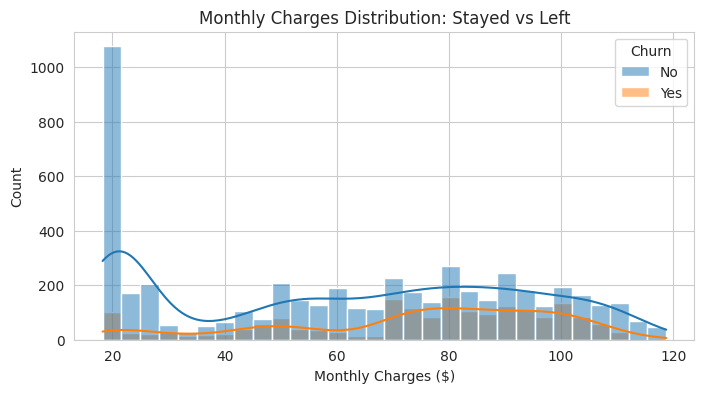

In [76]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x='MonthlyCharges', hue='Churn', bins=30, kde=True)
plt.title("Monthly Charges Distribution: Stayed vs Left")
plt.xlabel("Monthly Charges ($)")
plt.show()

**Observation:** Customers who left pay more on average (**$74.44** per month vs **$61.31**). Many customers who stayed are concentrated at low bills (around $20-$25), while churned customers cluster at higher bills (the median is about $80).

**Why it matters:** Higher bills are linked with a higher chance of leaving. This is an association, not proof of cause, since fiber optic customers pay the most and also churn the most.

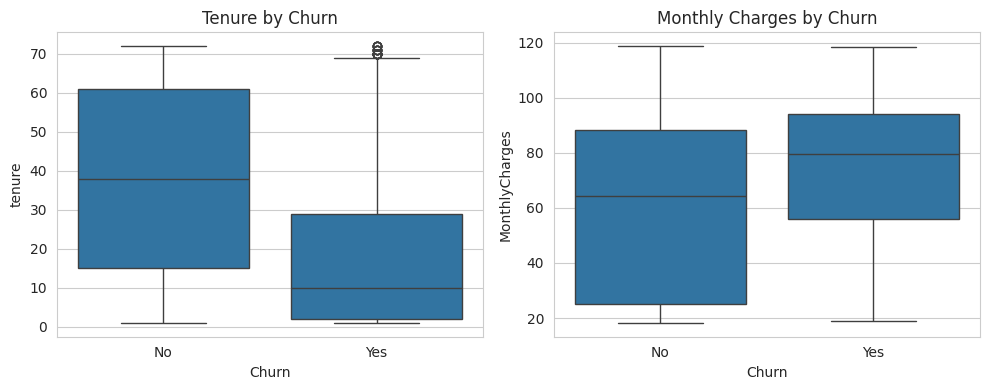

In [77]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.boxplot(x='Churn', y='tenure', data=df, ax=axes[0])
axes[0].set_title("Tenure by Churn")

sns.boxplot(x='Churn', y='MonthlyCharges', data=df, ax=axes[1])
axes[1].set_title("Monthly Charges by Churn")

plt.tight_layout()
plt.show()

**Observation:** The median tenure is **10 months** for customers who left and **38 months** for those who stayed. The median monthly charge is **$79.65**for customers who left and **$64.45** for those who stayed. Half of all churned customers left within their first 10 months, and a quarter left within just 2 months.

**Why it matters:** The medians show the same pattern as the averages, so the finding is not driven by a few unusual customers. The median gap in bills ($15) is larger than the gap in averages ($13), because many low-bill customers who stayed pull the average down.

In [78]:
print(df.groupby('Churn')[['tenure', 'MonthlyCharges']].median())
print()
print(df.groupby('Churn')[['tenure', 'MonthlyCharges']].describe().round(1).T)

       tenure  MonthlyCharges
Churn                        
No       38.0           64.45
Yes      10.0           79.65

Churn                     No     Yes
tenure         count  5163.0  1869.0
               mean     37.7    18.0
               std      24.1    19.5
               min       1.0     1.0
               25%      15.0     2.0
               50%      38.0    10.0
               75%      61.0    29.0
               max      72.0    72.0
MonthlyCharges count  5163.0  1869.0
               mean     61.3    74.4
               std      31.1    24.7
               min      18.2    18.8
               25%      25.1    56.2
               50%      64.4    79.6
               75%      88.5    94.2
               max     118.8   118.4


In [79]:
early = df[df['tenure'] <= 12]
print("Customers in first year:", len(early))
print("Churn rate in first year (%):", round(early['Churn_flag'].mean() * 100, 1))
print("Churn rate after first year (%):", round(df[df['tenure'] > 12]['Churn_flag'].mean() * 100, 1))

Customers in first year: 2175
Churn rate in first year (%): 47.7
Churn rate after first year (%): 17.1


**Observation:** There are **2,175** customers in their first year, and **47.7%** of them churned, compared with **17.1%** for customers who stayed longer than 12 months. First-year customers make up about 31% of the base, but roughly 55% of all churn (about 1,040 of 1,869 customers who left).

**Why it matters:** This confirms that most churn happens early in the relationship. Almost half of new customers leave within a year, which makes the first year the most important period for retention.

**Action:** Focus retention budgets and offers on customers in months 1-12.

In [80]:
df['tenure_group'] = pd.cut(df['tenure'],
                            bins=[0, 12, 24, 48, 72],
                            labels=['0-1 yr', '1-2 yrs', '2-4 yrs', '4-6 yrs'])

df['tenure_group'].value_counts().sort_index()

,count
tenure_group,
0-1 yr,2175
1-2 yrs,1024
2-4 yrs,1594
4-6 yrs,2239


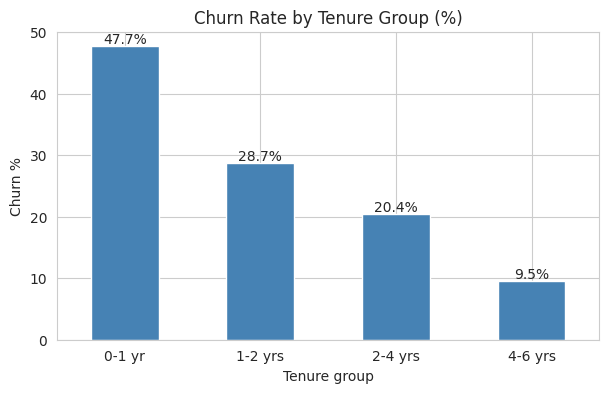

tenure_group
0-1 yr     47.7
1-2 yrs    28.7
2-4 yrs    20.4
4-6 yrs     9.5
Name: Churn_flag, dtype: float64


In [81]:
tenure_churn = df.groupby('tenure_group', observed=True)['Churn_flag'].mean() * 100

plt.figure(figsize=(7, 4))
ax = tenure_churn.plot(kind='bar', color='steelblue')
plt.title("Churn Rate by Tenure Group (%)")
plt.ylabel("Churn %")
plt.xlabel("Tenure group")
plt.xticks(rotation=0)

for i, v in enumerate(tenure_churn):
    ax.text(i, v + 0.5, f"{v:.1f}%", ha='center')

plt.show()
print(tenure_churn.round(1))

**Observation:** Churn falls steadily as tenure grows: **47.7%** for 0-1 year, **28.7%** for 1-2 years, **20.4%** for 2-4 years and **9.5%** for 4-6 years. New customers are 5 times more likely to leave than customers of 4+ years.

**Why it matters:** The longer a customer stays, the less likely they are to leave, so keeping customers through the early months pays off for years afterwards.

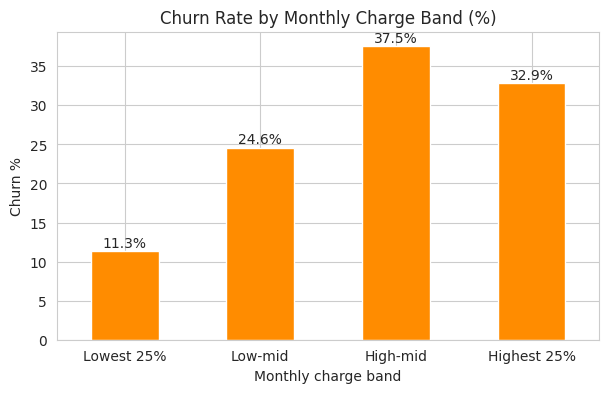

charge_band
Lowest 25%     11.3
Low-mid        24.6
High-mid       37.5
Highest 25%    32.9
Name: Churn_flag, dtype: float64


In [82]:
df['charge_band'] = pd.qcut(df['MonthlyCharges'], q=4,
                            labels=['Lowest 25%', 'Low-mid', 'High-mid', 'Highest 25%'])

charge_churn = df.groupby('charge_band', observed=True)['Churn_flag'].mean() * 100

plt.figure(figsize=(7, 4))
ax = charge_churn.plot(kind='bar', color='darkorange')
plt.title("Churn Rate by Monthly Charge Band (%)")
plt.ylabel("Churn %")
plt.xlabel("Monthly charge band")
plt.xticks(rotation=0)

for i, v in enumerate(charge_churn):
    ax.text(i, v + 0.5, f"{v:.1f}%", ha='center')

plt.show()
print(charge_churn.round(1))

**Observation:** Churn rises with bill size up to a point: **11.3%** for the lowest 25% of bills, **24.6%** for low-mid and **37.5%** for high-mid. The highest 25% of bills is slightly lower, at **32.9%**.

**Why it matters:** Customers with low bills rarely leave, and churn is highest in the upper-middle range. The pattern is not perfectly steady, so bill size alone doesn't fully explain churn. It is likely mixed with other factors such as service type and contract.

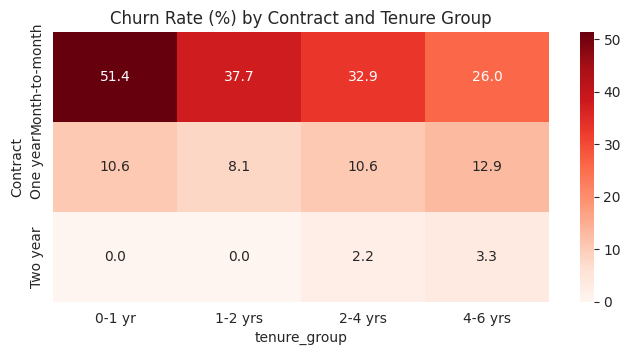

tenure                                 -0.35
Contract_Two year                      -0.30
OnlineSecurity_No internet service     -0.23
OnlineBackup_No internet service       -0.23
TechSupport_No internet service        -0.23
StreamingMovies_No internet service    -0.23
DeviceProtection_No internet service   -0.23
InternetService_No                     -0.23
MultipleLines_Yes                       0.04
StreamingMovies_Yes                     0.06
StreamingTV_Yes                         0.06
SeniorCitizen_Yes                       0.15
PaperlessBilling_Yes                    0.19
MonthlyCharges                          0.19
PaymentMethod_Electronic check          0.30
InternetService_Fiber optic             0.31
Name: Churn_flag, dtype: float64


In [86]:
pivot = df.pivot_table(values='Churn_flag', index='Contract',
                       columns='tenure_group', aggfunc='mean', observed=True) * 100

plt.figure(figsize=(8, 3.5))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Reds")
plt.title("Churn Rate (%) by Contract and Tenure Group")
plt.show()
print(top.round(2))

**Observation:** The riskiest group is month-to-month customers in their first year, with a churn rate of **51.4%**. Month-to-month churn falls with tenure (**37.7%**, **32.9%**, then **26.0%**) but stays high even after 4 years. One-year contracts stay between **8.1%** and **12.9%** at every tenure level, and two-year contracts are at **0.0%** for the first two years and only **2.2-3.3%** after that.

**Why it matters:** Contract type matters more than tenure on its own. Even a long-standing month-to-month customer (26.0%) is more likely to leave than a one-year customer at any stage. Two-year customers are almost never lost, though some of this may simply be that they are locked in for the contract term.

**Action:** Target new month-to-month customers first, and offer discounts to move them onto longer contracts early in their first year.

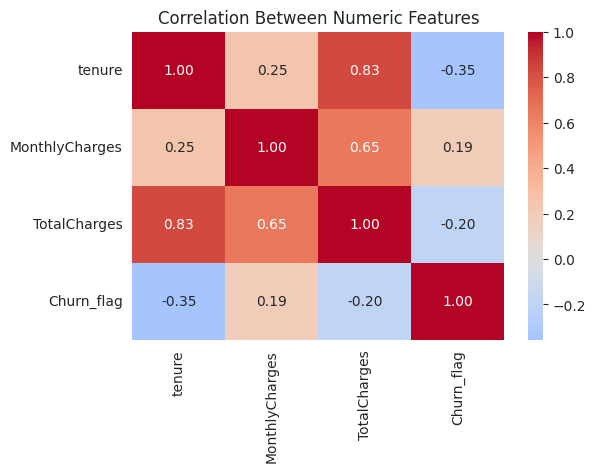

tenure_group    0-1 yr  1-2 yrs  2-4 yrs  4-6 yrs
Contract                                         
Month-to-month    51.4     37.7     32.9     26.0
One year          10.6      8.1     10.6     12.9
Two year           0.0      0.0      2.2      3.3
                tenure  MonthlyCharges  TotalCharges  Churn_flag
tenure            1.00            0.25          0.83       -0.35
MonthlyCharges    0.25            1.00          0.65        0.19
TotalCharges      0.83            0.65          1.00       -0.20
Churn_flag       -0.35            0.19         -0.20        1.00
tenure                                 -0.35
Contract_Two year                      -0.30
OnlineSecurity_No internet service     -0.23
OnlineBackup_No internet service       -0.23
TechSupport_No internet service        -0.23
StreamingMovies_No internet service    -0.23
DeviceProtection_No internet service   -0.23
InternetService_No                     -0.23
MultipleLines_Yes                       0.04
StreamingMovies_Yes 

In [87]:
num_df = df[['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn_flag']]

plt.figure(figsize=(6, 4))
sns.heatmap(num_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Between Numeric Features")
plt.show()
print(pivot.round(1))
print(num_df.corr().round(2))
print(top.round(2))

**Observation:** Tenure has the strongest link with churn of the numeric columns (**-0.35**): the longer the tenure, the lower the churn. Monthly charges have a weak positive link (**+0.19**), and total charges a weak negative one (**-0.20**). Tenure and total charges are strongly related (**0.83**), and monthly and total charges moderately so (**0.65**).

**Why it matters:** Total charges is mostly a reflection of tenure, which explains its negative link with churn. It adds little new information beyond tenure and monthly charges, so I will keep this overlap in mind when building the model.

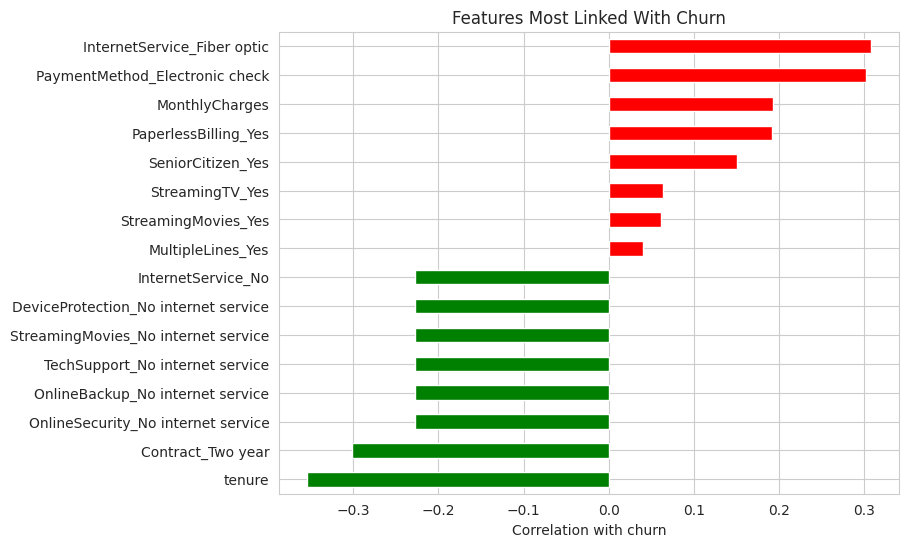

tenure                                 -0.35
Contract_Two year                      -0.30
OnlineSecurity_No internet service     -0.23
OnlineBackup_No internet service       -0.23
TechSupport_No internet service        -0.23
StreamingMovies_No internet service    -0.23
DeviceProtection_No internet service   -0.23
InternetService_No                     -0.23
MultipleLines_Yes                       0.04
StreamingMovies_Yes                     0.06
StreamingTV_Yes                         0.06
SeniorCitizen_Yes                       0.15
PaperlessBilling_Yes                    0.19
MonthlyCharges                          0.19
PaymentMethod_Electronic check          0.30
InternetService_Fiber optic             0.31
Name: Churn_flag, dtype: float64


In [85]:
df_enc = pd.get_dummies(
    df.drop(columns=['Churn', 'tenure_group', 'charge_band']),
    drop_first=True, dtype=int
)

corr_churn = df_enc.corr()['Churn_flag'].drop('Churn_flag').sort_values()

top = pd.concat([corr_churn.head(8), corr_churn.tail(8)])

plt.figure(figsize=(8, 6))
top.plot(kind='barh', color=['green' if v < 0 else 'red' for v in top])
plt.title("Features Most Linked With Churn")
plt.xlabel("Correlation with churn")
plt.show()

print(top.round(2))

## Key Insights

1. **Contract type is the strongest driver.** Month-to-month customers churn at 42.7%, compared with 2.8% for two-year contracts, and make up about 89% of all churned customers.
2. **The first year is the riskiest period.** First-year customers churn at 47.7%, compared with 17.1% after the first year, and churn drops to 9.5% for customers of 4+ years.
3. **Fiber optic customers churn at 41.9%**, versus 19.0% for DSL, and also pay the highest monthly bills.
4. **Add-on services are linked with lower churn.** Customers without tech support or online security churn at about 42%, compared with about 15% for those who have them.
5. **Electronic check users churn at 45.3%**, about 3 times the rate of customers on automatic payment.
6. **Higher bills are linked with higher churn up to a point.** Churn rises from 11.3% for the lowest bills to 37.5% for upper-middle bills, and is 32.9% for the highest.

## Recommendations
- Move month-to-month customers onto longer contracts with discounts or perks.
- Build an onboarding program focused on months 1-12.
- Bundle tech support and online security into plans.
- Encourage electronic check customers to switch to automatic payment.
- Review fiber optic pricing and service quality.

## Next Step
Use these findings to build a model that predicts which customers are likely to churn.